<a href="https://colab.research.google.com/github/scudilio/AI---Deep-Learning/blob/main/Aula%204/MBA_DL_Aula4_03_rag_documentos_da_empresa.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aula 4 | Case 2: RAG, o modelo responde com os documentos da empresa

**MBA FIAP | Deep Learning e Redes Neurais Modernas | Profa. Juliana Scudilio**

**Problema de negócio.** O cliente pergunta no chat: "quantos dias tenho para trocar?". A resposta está na política da loja, que o LLM nunca leu. Treinar o modelo com a política é caro, lento e a política muda todo mês. Precisamos de um jeito de o modelo **consultar** o documento na hora de responder.

**A ideia do método.** RAG = *Retrieval-Augmented Generation*, geração aumentada por busca. Três passos: (1) quebrar os documentos em pedaços e transformar cada pedaço em um vetor (embedding, aula 3); (2) quando chega a pergunta, transformá-la em vetor e buscar os pedaços mais parecidos; (3) colocar esses pedaços **dentro do prompt** e pedir que o modelo responda só com base neles. Nenhum peso do modelo muda. O conhecimento fica nos documentos, que podem ser trocados a qualquer hora.

**O que vamos ver.** O mesmo LLM do case 1 errando sem os documentos e acertando com eles; a busca por similaridade funcionando (e falhando); o que acontece quando a resposta não está nos documentos; e por que não dá para simplesmente colar todos os documentos no prompt.

**Documentos.** Uma política de trocas, frete e atendimento de uma loja **fictícia** ("Loja Horizonte"), escrita para esta aula. Em projeto, seriam PDFs, páginas da intranet, manuais.

**Roteiro (45 min).** 0. Preparar → 1. O LLM sem os documentos → 2. Os documentos em pedaços → 3. Pedaços em vetores → 4. Buscar → 5. Responder com contexto → 6. Quando a resposta não existe → 7. Avaliar em lote → 8. Janela de contexto e custo → 9. Guardar.

## 0. Preparar o ambiente

Duas bibliotecas novas em relação ao case 1:

- `sentence-transformers`: modelos que transformam uma frase inteira em um vetor (no notebook 00 fizemos isso à mão com a média dos tokens do BERT; aqui é um modelo treinado especificamente para que frases parecidas fiquem perto);
- o LLM é o mesmo `Qwen2.5-0.5B-Instruct` do case 1.

Não usamos LangChain nem banco vetorial: com poucas dezenas de pedaços, uma matriz numpy faz a busca. Ao final discutimos quando essas ferramentas entram.

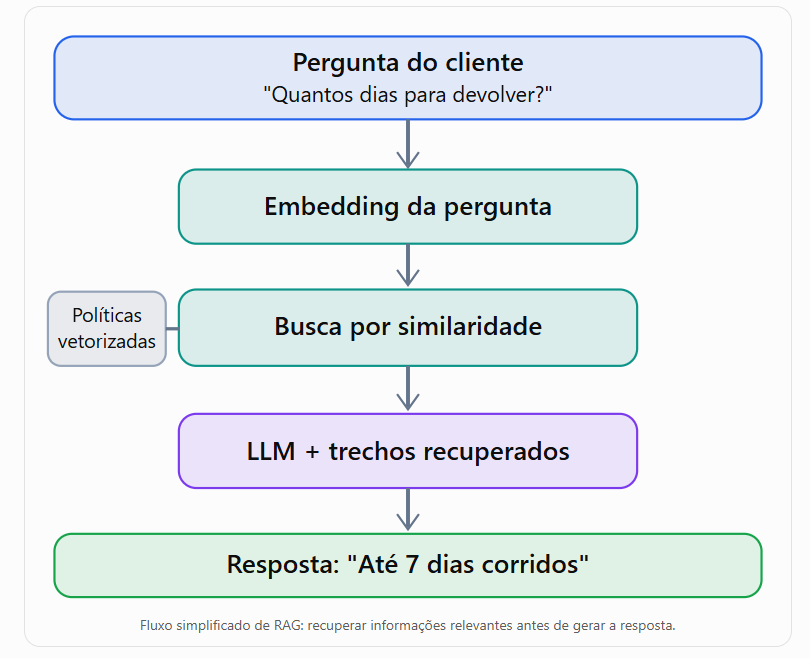

In [1]:
%pip install -q "transformers>=4.56" sentence-transformers accelerate

import re                                  # expressões regulares: achar números na resposta
import time                                # cronometrar
import numpy as np                         # vetores e produto escalar
import pandas as pd                        # tabelas
import torch                               # motor numérico
from transformers import AutoTokenizer, AutoModelForCausalLM
from sentence_transformers import SentenceTransformer

torch.manual_seed(0)

NOME_LLM = "Qwen/Qwen2.5-0.5B-Instruct"    # o mesmo LLM do case 1
tok = AutoTokenizer.from_pretrained(NOME_LLM)
llm = AutoModelForCausalLM.from_pretrained(NOME_LLM, dtype=torch.float32)
llm.eval()

def perguntar(mensagens, max_novos=120, mostrar=True):
    # a mesma função do case 1: conversa -> texto no formato do modelo -> tokens -> geração -> texto
    texto = tok.apply_chat_template(mensagens, tokenize=False, add_generation_prompt=True)
    entrada = tok(texto, return_tensors="pt")
    n_entrada = entrada["input_ids"].shape[1]
    t0 = time.time()
    with torch.no_grad():
        saida = llm.generate(**entrada, max_new_tokens=max_novos, do_sample=False, pad_token_id=tok.eos_token_id)
    resposta = tok.decode(saida[0][n_entrada:], skip_special_tokens=True).strip()
    if mostrar:
        print(f"[{n_entrada} tokens de entrada, {time.time() - t0:.1f} s]\n{resposta}")
    return resposta

print("LLM carregado | GPU?", torch.cuda.is_available())

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

LLM carregado | GPU? False


## 1. O LLM sem os documentos

Pergunta de cliente, direta. O modelo nunca viu a política da Loja Horizonte. Repare no que ele faz: ou diz que não sabe, ou responde com uma regra genérica "que costuma valer". As duas coisas são inúteis para o atendimento, e a segunda é perigosa: parece uma resposta.

In [2]:
PERGUNTA = "Comprei na Loja Horizonte e me arrependi. Quantos dias tenho para devolver o produto?"

r = perguntar([{"role": "user", "content": PERGUNTA}], max_novos=90)

[56 tokens de entrada, 60.2 s]
Como assistente de inteligência artificial, eu não tenho acesso a informações pessoais ou detalhes específicos sobre um pedido em uma loja física como a Loja Horizonte. No entanto, posso fornecer algumas informações gerais sobre o processo de devolução:

1. O prazo de devolução geralmente é de 30 dias após o vencimento do produto.

2. Se você tiver um


## 2. Os documentos, em pedaços

A política da loja, escrita em 14 parágrafos. Cada parágrafo vira um **pedaço** (*chunk*). Em projeto real, os documentos são longos e o corte é uma decisão: pedaços pequenos são precisos mas perdem contexto; pedaços grandes carregam contexto mas diluem a busca. Um ponto de partida comum: 200 a 500 palavras com sobreposição entre pedaços vizinhos.

Aqui cada parágrafo já é uma unidade de sentido, então o corte é por parágrafo.

In [3]:
POLITICA = '''
Direito de arrependimento: compras feitas no site ou no aplicativo da Loja Horizonte podem ser devolvidas em até 7 dias corridos após o recebimento, sem necessidade de justificativa. O produto deve estar sem uso, na embalagem original, com todos os acessórios. O reembolso é feito em até 10 dias úteis após a chegada do produto ao nosso centro de distribuição.

Produto com defeito: para produtos não duráveis (vestuário, calçados, perfumaria), o prazo para solicitar troca ou reembolso por defeito é de 30 dias após o recebimento. Para produtos duráveis (eletrodomésticos, eletrônicos, móveis), o prazo é de 90 dias. O cliente escolhe entre troca pelo mesmo produto, crédito na loja ou reembolso.

Frete grátis: pedidos acima de R$ 199 têm frete grátis para as regiões Sul e Sudeste. Para as regiões Norte, Nordeste e Centro-Oeste, o frete é grátis em pedidos acima de R$ 299. Abaixo desses valores, o frete é calculado pelo CEP no fechamento do pedido.

Prazo de entrega: capitais e regiões metropolitanas recebem em 3 a 5 dias úteis após a aprovação do pagamento. Demais cidades, em 5 a 10 dias úteis. O prazo exato aparece na página do produto ao informar o CEP.

Atendimento: o SAC da Loja Horizonte funciona por telefone de segunda a sexta, das 8h às 20h, e aos sábados das 9h às 15h. O chat no site e no aplicativo funciona 24 horas, com atendente humano das 8h às 22h e assistente virtual fora desse horário.

Pagamento: aceitamos cartão de crédito em até 10 vezes sem juros para compras acima de R$ 500 (até 6 vezes abaixo desse valor), Pix com 5% de desconto e boleto bancário, com compensação em até 2 dias úteis.

Garantia estendida: pode ser contratada para eletrodomésticos e eletrônicos em até 30 dias após a compra, com cobertura de 12 ou 24 meses além da garantia do fabricante. O valor aparece na página do produto.

Avaria no transporte: se a embalagem chegar visivelmente danificada, recuse o recebimento. Se a avaria for percebida depois, registre pelo aplicativo em até 48 horas após a entrega, com fotos do produto e da embalagem.

Troca de tamanho ou cor: para vestuário e calçados, a primeira troca de tamanho ou cor é gratuita e pode ser solicitada em até 30 dias após o recebimento, com o produto sem uso e com etiqueta.

Cupom de primeira compra: clientes novos recebem 10% de desconto na primeira compra, limitado a R$ 50, usando o cupom BEMVINDO no fechamento do pedido. Não é acumulável com outras promoções.

Nota fiscal: a nota fiscal eletrônica é enviada por e-mail no momento do faturamento. A segunda via pode ser baixada na área "Meus pedidos" do site a qualquer momento.

Dados pessoais: o cliente pode solicitar a exclusão dos seus dados pessoais pelo formulário de privacidade do site. A exclusão é concluída em até 15 dias, exceto dados que a lei obriga a guardar, como notas fiscais.

Vendedores parceiros (marketplace): produtos vendidos por parceiros seguem o prazo de arrependimento de 7 dias da Loja Horizonte. Prazos de entrega e políticas de defeito podem variar e estão descritos na página de cada parceiro.

Produto indisponível após a compra: se o produto ficar indisponível depois do pedido, o cliente é avisado por e-mail, o pedido é cancelado e o estorno é feito em até 5 dias úteis no mesmo meio de pagamento.
'''

pedacos = [p.strip() for p in POLITICA.strip().split("\n\n")]     # separa pelos parágrafos (linha em branco)
print(len(pedacos), "pedaços")
for i, p in enumerate(pedacos):
    print(f"[{i:2d}] {p[:95]}...")

14 pedaços
[ 0] Direito de arrependimento: compras feitas no site ou no aplicativo da Loja Horizonte podem ser ...
[ 1] Produto com defeito: para produtos não duráveis (vestuário, calçados, perfumaria), o prazo para...
[ 2] Frete grátis: pedidos acima de R$ 199 têm frete grátis para as regiões Sul e Sudeste. Para as r...
[ 3] Prazo de entrega: capitais e regiões metropolitanas recebem em 3 a 5 dias úteis após a aprovaçã...
[ 4] Atendimento: o SAC da Loja Horizonte funciona por telefone de segunda a sexta, das 8h às 20h, e...
[ 5] Pagamento: aceitamos cartão de crédito em até 10 vezes sem juros para compras acima de R$ 500 (...
[ 6] Garantia estendida: pode ser contratada para eletrodomésticos e eletrônicos em até 30 dias após...
[ 7] Avaria no transporte: se a embalagem chegar visivelmente danificada, recuse o recebimento. Se a...
[ 8] Troca de tamanho ou cor: para vestuário e calçados, a primeira troca de tamanho ou cor é gratui...
[ 9] Cupom de primeira compra: clientes novos recebem

## 3. Pedaços em vetores

O modelo `intfloat/multilingual-e5-small` transforma qualquer frase (em português, inglês e mais 90 línguas) em um vetor de 384 números. Frases com o mesmo sentido ficam com vetores parecidos, mesmo com palavras diferentes: "devolver o produto" fica perto de "direito de arrependimento". É o que o TF-IDF da aula 3 não fazia.

Detalhe deste modelo: ele foi treinado com os prefixos `passage: ` para documentos e `query: ` para perguntas. Sem os prefixos, funciona pior.

`normalize_embeddings=True` deixa todos os vetores com comprimento 1. Com isso, a similaridade de cosseno vira um simples produto escalar (notebook 00).

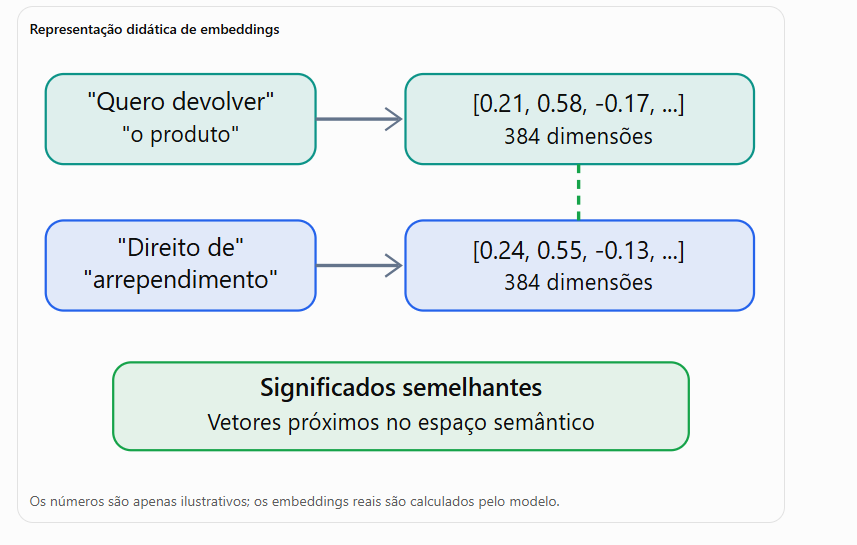

In [4]:
NOME_EMB = "intfloat/multilingual-e5-small"
emb = SentenceTransformer(NOME_EMB)                                  # baixa o modelo de embeddings (cerca de 470 MB)

t0 = time.time()
V = emb.encode(["passage: " + p for p in pedacos], normalize_embeddings=True)   # uma linha por pedaço
print("Matriz de vetores:", V.shape, f"| {time.time() - t0:.1f} s")
print("Primeiros números do pedaço 0:", np.round(V[0][:6], 3))
print("Comprimento do vetor (norma):", round(float(np.linalg.norm(V[0])), 3))

modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/498k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

model.safetensors: downloading bytes:           |  0.00B            

... (5 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/167 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]

Matriz de vetores: (14, 384) | 2.6 s
Primeiros números do pedaço 0: [ 0.018 -0.034  0.016 -0.115  0.067 -0.054]
Comprimento do vetor (norma): 1.0


## 4. Buscar: a pergunta vira vetor e encontra os pedaços mais parecidos

`V @ q` multiplica a matriz dos pedaços pelo vetor da pergunta: devolve um número por pedaço, a similaridade de cosseno. `argsort` ordena; pegamos os 3 maiores. Esses 3 pedaços são o **contexto** que vai para o LLM.

Repare: a pergunta diz "devolver" e "me arrependi"; o pedaço escolhido diz "direito de arrependimento" e "devolvidas". Busca por sentido, não por palavra.

In [5]:
K = 3                                                                # quantos pedaços levar para o prompt

q = emb.encode(["query: " + PERGUNTA], normalize_embeddings=True)[0]   # vetor da pergunta (com o prefixo "query: ")
similaridade = V @ q                                                 # cosseno entre a pergunta e cada pedaço
melhores = np.argsort(similaridade)[::-1][:K]                        # índices dos K maiores

print("Pergunta:", PERGUNTA, "\n")
for i in melhores:
    print(f"[{i:2d}] similaridade {similaridade[i]:.3f} | {pedacos[i][:110]}...")

Pergunta: Comprei na Loja Horizonte e me arrependi. Quantos dias tenho para devolver o produto? 

[ 0] similaridade 0.931 | Direito de arrependimento: compras feitas no site ou no aplicativo da Loja Horizonte podem ser devolvidas em a...
[12] similaridade 0.902 | Vendedores parceiros (marketplace): produtos vendidos por parceiros seguem o prazo de arrependimento de 7 dias...
[ 1] similaridade 0.882 | Produto com defeito: para produtos não duráveis (vestuário, calçados, perfumaria), o prazo para solicitar troc...


## 5. Responder com o contexto no prompt

O prompt tem três partes: as regras (`system`), o contexto (os pedaços encontrados) e a pergunta. A frase "Se a resposta não estiver no contexto, diga que não encontrou" é a defesa contra invenção; não é garantia, é redução de risco.

Compare com a resposta da seção 1.

In [6]:
REGRAS_RAG = ("Você é o assistente de atendimento da Loja Horizonte. Responda em português, em no máximo 3 frases, "
              "usando SOMENTE as informações do contexto abaixo. Se a resposta não estiver no contexto, "
              "diga que não encontrou essa informação na política da loja.")

contexto = "\n\n".join(pedacos[i] for i in melhores)                 # junta os K pedaços

mensagens = [{"role": "system", "content": REGRAS_RAG + "\n\nContexto:\n" + contexto},
             {"role": "user", "content": PERGUNTA}]
r = perguntar(mensagens)

[370 tokens de entrada, 23.5 s]
Se você comprou no site ou aplicativo da Loja Horizonte e teve problemas, pode devolver o produto em até 7 dias corridos após o recebimento.


### Validar: os números da resposta estão no contexto?

Validação mínima e automática: todo número que aparece na resposta tem que aparecer no contexto. Um "15 dias" inventado não passa. Em projeto, esta checagem roda em toda resposta antes de chegar ao cliente.

In [7]:
numeros_resposta = set(re.findall(r"\d+", r))                        # todos os números na resposta
numeros_contexto = set(re.findall(r"\d+", contexto))                 # todos os números no contexto
inventados = numeros_resposta - numeros_contexto

print("Números na resposta:", sorted(numeros_resposta))
print("Fora do contexto   :", sorted(inventados) if inventados else "nenhum: todos os números vieram do documento")

Números na resposta: ['7']
Fora do contexto   : nenhum: todos os números vieram do documento


## 6. Quando a resposta não existe nos documentos

Pergunta fora da política. O que queremos: o modelo diz que não encontrou. O que pode acontecer com um modelo pequeno: ele responde algo "razoável". Veja também a similaridade dos pedaços encontrados: baixa em relação às perguntas anteriores. Duas defesas, aplicadas em sequência: um **limiar de similaridade** barra a pergunta antes do LLM ("não encontrei; vou transferir para um atendente"), e a checagem de números da seção anterior pega o que passar.

In [8]:
FORA = "A Loja Horizonte entrega para o exterior? Quanto custa o frete para Portugal?"

q = emb.encode(["query: " + FORA], normalize_embeddings=True)[0]
similaridade = V @ q
melhores = np.argsort(similaridade)[::-1][:K]
for i in melhores:
    print(f"[{i:2d}] similaridade {similaridade[i]:.3f} | {pedacos[i][:90]}...")

contexto = "\n\n".join(pedacos[i] for i in melhores)
print()
r = perguntar([{"role": "system", "content": REGRAS_RAG + "\n\nContexto:\n" + contexto},
               {"role": "user", "content": FORA}])

# as duas defesas, aplicadas à resposta acima
inventados = set(re.findall(r"\d+", r)) - set(re.findall(r"\d+", contexto))
print("\nNúmeros fora do contexto:", sorted(inventados) if inventados else "nenhum")
LIMIAR = 0.87                                                        # exemplo de regra; em projeto, calibrar no gabarito
print(f"Maior similaridade: {similaridade.max():.3f} | limiar {LIMIAR} -> {'responder' if similaridade.max() >= LIMIAR else 'NÃO responder: transferir para atendente'}")

[ 2] similaridade 0.848 | Frete grátis: pedidos acima de R$ 199 têm frete grátis para as regiões Sul e Sudeste. Para...
[ 0] similaridade 0.840 | Direito de arrependimento: compras feitas no site ou no aplicativo da Loja Horizonte podem...
[ 4] similaridade 0.839 | Atendimento: o SAC da Loja Horizonte funciona por telefone de segunda a sexta, das 8h às 2...

[370 tokens de entrada, 13.5 s]
Sim, a Loja Horizonte entrega para o exterior. O frete para Portugal custa R$ 60,00.

Números fora do contexto: ['00', '60']
Maior similaridade: 0.848 | limiar 0.87 -> NÃO responder: transferir para atendente


## 7. Avaliar em lote: perguntas com resposta conhecida

Avaliar RAG é avaliar duas coisas separadas: a **busca** achou o pedaço certo? A **resposta** usou o pedaço certo? Montamos um gabarito com o pedaço esperado de cada pergunta e medimos a busca automaticamente. A resposta, lemos.

Em projeto, este gabarito é o ativo mais valioso do sistema: 50 a 100 perguntas reais com resposta validada por quem conhece o negócio.

In [9]:
gabarito = [
    ("Quantos dias tenho para devolver um produto que não gostei?", 0),
    ("Minha geladeira apresentou defeito dois meses depois da entrega. Ainda posso trocar?", 1),
    ("Moro em Recife. A partir de quanto o frete é grátis?", 2),
    ("O telefone do SAC atende no sábado?", 4),
    ("Comprei uma camisa e veio pequena. A troca é cobrada?", 8),
    ("Quanto tempo demora o estorno se o produto ficar indisponível depois da compra?", 13),
]

acertos_busca = 0
linhas = []
for pergunta, esperado in gabarito:
    q = emb.encode(["query: " + pergunta], normalize_embeddings=True)[0]
    similaridade = V @ q
    melhores = np.argsort(similaridade)[::-1][:K]
    achou = esperado in melhores                                      # o pedaço certo está entre os K?
    acertos_busca += achou
    contexto = "\n\n".join(pedacos[i] for i in melhores)
    resposta = perguntar([{"role": "system", "content": REGRAS_RAG + "\n\nContexto:\n" + contexto},
                          {"role": "user", "content": pergunta}], mostrar=False)
    melhores = [int(i) for i in melhores]                               # numpy -> int, só para imprimir limpo
    linhas.append([pergunta, esperado, melhores, "sim" if achou else "NÃO", resposta])
    print(f"P: {pergunta}\n   pedaços {melhores} (esperado {esperado}) | busca {'ok' if achou else 'ERROU'}\n   R: {resposta}\n")

print(f"Busca: pedaço certo entre os {K} primeiros em {acertos_busca} de {len(gabarito)} perguntas")

P: Quantos dias tenho para devolver um produto que não gostei?
   pedaços [1, 0, 12] (esperado 0) | busca ok
   R: O prazo para devolução de um produto que você não goste pode variar dependendo do prazo de arrependimento específico fornecido pela Loja Horizonte. No entanto, geralmente, o prazo de devolução é de 7 dias corridos após o recebimento.

P: Minha geladeira apresentou defeito dois meses depois da entrega. Ainda posso trocar?
   pedaços [1, 6, 7] (esperado 1) | busca ok
   R: Sim, você ainda pode trocar o produto.

P: Moro em Recife. A partir de quanto o frete é grátis?
   pedaços [2, 8, 5] (esperado 2) | busca ok
   R: O frete é gratuito para pedidos acima de R$ 199 nos sul e sudeste, e R$ 299 nos norte, nordeste e centro-oeste.

P: O telefone do SAC atende no sábado?
   pedaços [4, 8, 7] (esperado 4) | busca ok
   R: Sim, o SAC atende no sábado.

P: Comprei uma camisa e veio pequena. A troca é cobrada?
   pedaços [8, 1, 9] (esperado 8) | busca ok
   R: Não, a troca é cobrada 

⏱ **Checkpoint:** quantas das 6 perguntas tiveram o pedaço certo na busca? Em qual resposta o modelo misturou informação de outro pedaço?

## 8. Por que não colar tudo no prompt: janela de contexto e custo

A política inteira tem poucas centenas de tokens; caberia no prompt. Então por que buscar? Por três motivos que aparecem quando o documento cresce: (1) a janela de contexto tem limite; (2) cada token do prompt custa tempo e dinheiro **em toda pergunta**; (3) com muito texto irrelevante no prompt, o modelo erra mais ("perde a agulha no palheiro").

Conte os tokens: a política inteira contra 3 pedaços. Agora imagine 2.000 páginas de manual.

In [10]:
tokens_tudo = len(tok(POLITICA)["input_ids"])
tokens_3 = len(tok("\n\n".join(pedacos[i] for i in melhores))["input_ids"])
print(f"Política inteira: {tokens_tudo} tokens | 3 pedaços: {tokens_3} tokens | economia por pergunta: {1 - tokens_3 / tokens_tudo:.0%}")
print(f"Janela de contexto deste modelo: {llm.config.max_position_embeddings:,} tokens")
print(f"Um manual de 2.000 páginas (~500 palavras por página, ~1,5 token por palavra em português): ~{2000 * 500 * 1.5 / 1e6:.1f} milhão de tokens. Não cabe. E se coubesse, custaria isso por pergunta.")

Política inteira: 967 tokens | 3 pedaços: 219 tokens | economia por pergunta: 77%
Janela de contexto deste modelo: 32,768 tokens
Um manual de 2.000 páginas (~500 palavras por página, ~1,5 token por palavra em português): ~1.5 milhão de tokens. Não cabe. E se coubesse, custaria isso por pergunta.


### O que o LangChain (e similares) fariam aqui

Tudo que fizemos cabe em 30 linhas: cortar, vetorizar, buscar, montar o prompt, gerar. Bibliotecas como LangChain, LlamaIndex e LangGraph empacotam exatamente esses passos, com conectores prontos (PDF, SharePoint, bancos vetoriais como FAISS, Chroma, pgvector) e, no caso do LangGraph, fluxos com várias etapas e decisões (agentes). Vale usar quando há muitos conectores ou fluxos complexos; não vale para entender o método, e não é obrigatório para colocar um RAG em produção. O que decide a qualidade é o que vimos: o corte dos documentos, o modelo de embeddings, o K, o prompt e o gabarito de avaliação.

## 9. Guardar o resultado

Em RAG, o "modelo" é a soma de várias escolhas. Todas precisam de versão: o modelo de embeddings, o corte, o K, o prompt, o LLM e o gabarito com o resultado.

In [11]:
import json
resultado = {
    "llm": NOME_LLM,
    "embeddings": NOME_EMB,
    "n_pedacos": len(pedacos),
    "k": K,
    "prompt": REGRAS_RAG,
    "busca_acertos": f"{acertos_busca}/{len(gabarito)}",
    "respostas": [{"pergunta": l[0], "pedacos": [int(i) for i in l[2]], "resposta": l[4]} for l in linhas],
}
json.dump(resultado, open("resultado_case2_rag.json", "w"), indent=2, ensure_ascii=False)
np.save("vetores_politica.npy", V)                                   # os vetores dos pedaços (em projeto: um banco vetorial)
print("Salvo: resultado_case2_rag.json, vetores_politica.npy")

Salvo: resultado_case2_rag.json, vetores_politica.npy


## Para discutir

1. A política muda amanhã: "arrependimento passa a 15 dias". O que precisa ser refeito no RAG? E se fosse um modelo fine-tuned com a política?
2. Que documentos da sua empresa viram um RAG em um mês? Quem valida o gabarito?
3. O modelo respondeu com confiança uma vez em que a busca trouxe o pedaço errado. Que controle você colocaria antes de a resposta chegar ao cliente?

**Próximo case:** quando o problema não é conhecimento, e sim **comportamento**: ajustar os pesos com LoRA.